# 08_02 KL Divergence and Jensen-Shannon Divergence

**Learning objectives**
- Define the **Kullback-Leibler divergence** $\mathrm{KL}(p\|q)$ and the **Jensen-Shannon divergence**, compute them for discrete and Gaussian distributions, and read them as "extra surprise" and as a distance-like score.
- Explain the **asymmetry** of KL and the difference between **forward** (mode-covering) and **reverse** (mode-seeking) KL.
- Prove $\mathrm{KL}\ge0$, derive the Gaussian formula, and connect KL to maximum likelihood, the **G-test** and the **chi-square** statistic.
- Use KL, JS and the **population stability index (PSI)** to monitor **data drift**.

**Prerequisites:** [08_01 Entropy and cross-entropy](08_01_entropy_cross_entropy.ipynb), [02_05 Normal distribution](../../module_02_continuous/notebooks/02_05_normal.ipynb), [06_03 Hypothesis testing](../../module_06_inference/notebooks/06_03_hypothesis_testing_core.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
From 08_01: entropy $H(p)=-\sum p\ln p$, cross-entropy $H(p,q)=-\sum p\ln q$, and the identity $H(p,q)=H(p)+\mathrm{KL}(p\|q)$. A Gaussian density is $\varphi(x;\mu,\sigma)=\frac{1}{\sigma\sqrt{2\pi}}e^{-(x-\mu)^2/(2\sigma^2)}$. A chi-square statistic with $K-1$ degrees of freedom tests whether observed counts match a distribution (06_04).

## 3. Intuition and story
You trained a model on last year's customers. This week's customers look a bit different: are they different **enough** to worry? You need a number that says how far the new distribution $q$ is from the old one $p$. The KL divergence answers a precise question: *if the data really follow $p$ but I act as if they follow $q$, how many extra nats of surprise do I pay per observation?* It is zero only if $q=p$.

KL is not a distance: $\mathrm{KL}(p\|q)\ne\mathrm{KL}(q\|p)$, and it explodes when $q$ gives (near) zero probability to something $p$ can produce. The **Jensen-Shannon divergence** repairs both flaws by comparing each distribution with their average: it is symmetric, always finite (at most $\ln2$), and its square root is a true metric.

## 4. Formal definitions

| Quantity | Definition |
|---|---|
| **KL divergence** (discrete) | $\mathrm{KL}(p\|q)=\sum_kp_k\ln\dfrac{p_k}{q_k}=H(p,q)-H(p)$ |
| **KL divergence** (continuous) | $\mathrm{KL}(f\|g)=\int f(x)\ln\dfrac{f(x)}{g(x)}\,dx$ |
| **Jensen-Shannon** | $\mathrm{JS}(p,q)=\tfrac12\mathrm{KL}(p\|m)+\tfrac12\mathrm{KL}(q\|m)$, $m=\tfrac12(p+q)$ |
| **PSI** (population stability index) | $\mathrm{PSI}=\sum_k(q_k-p_k)\ln\dfrac{q_k}{p_k}=\mathrm{KL}(p\|q)+\mathrm{KL}(q\|p)$ |
| **Total variation** | $\mathrm{TV}(p,q)=\tfrac12\sum_k|p_k-q_k|$ |

**Gaussians:** $\ \mathrm{KL}\big(N(\mu_1,\sigma_1^2)\|N(\mu_2,\sigma_2^2)\big)=\ln\dfrac{\sigma_2}{\sigma_1}+\dfrac{\sigma_1^2+(\mu_1-\mu_2)^2}{2\sigma_2^2}-\dfrac12$.

**Facts:** $\mathrm{KL}\ge0$ with equality iff $p=q$; $0\le\mathrm{JS}\le\ln2$; $\sqrt{\mathrm{JS}}$ is a metric; **Pinsker:** $\mathrm{TV}\le\sqrt{\mathrm{KL}/2}$; for small differences $\mathrm{KL}(p\|q)\approx\tfrac12\sum_k\frac{(p_k-q_k)^2}{q_k}$.

## 5. Derivations

### 5.1 $\mathrm{KL}\ge0$ (Gibbs' inequality)
$-\mathrm{KL}(p\|q)=\sum_kp_k\ln\frac{q_k}{p_k}\le\ln\sum_kp_k\frac{q_k}{p_k}\le\ln1=0$ by Jensen's inequality for the concave $\ln$; equality needs $q_k/p_k$ constant, i.e. $q=p$. **In plain words.** Acting on a wrong model can only cost extra surprise on average; the best possible model is the truth.

### 5.2 Gaussian formula
With $f=N(\mu_1,\sigma_1^2)$, $g=N(\mu_2,\sigma_2^2)$: $\ln\frac fg=\ln\frac{\sigma_2}{\sigma_1}-\frac{(x-\mu_1)^2}{2\sigma_1^2}+\frac{(x-\mu_2)^2}{2\sigma_2^2}$. Under $f$, $E[(x-\mu_1)^2]=\sigma_1^2$ and $E[(x-\mu_2)^2]=\sigma_1^2+(\mu_1-\mu_2)^2$, so $\mathrm{KL}=\ln\frac{\sigma_2}{\sigma_1}-\frac12+\frac{\sigma_1^2+(\mu_1-\mu_2)^2}{2\sigma_2^2}$. **In plain words.** The cost has a location part (distance of the means in units of $\sigma_2$) and a scale part (a mismatch of the spreads, which punishes a $g$ narrower than $f$ more than a $g$ wider than $f$).

### 5.3 KL and maximum likelihood
For data from $p$ and a model $q_\theta$, $\mathrm{KL}(p\|q_\theta)=-H(p)-E_p[\ln q_\theta]$; the first term does not depend on $\theta$, so **maximising the expected log-likelihood is minimising $\mathrm{KL}(p\|q_\theta)$**. The maximum-likelihood estimate is the model closest to the data distribution in KL (06_01, 08_01). **In plain words.** Fitting a model by maximum likelihood is choosing the one that is least surprised by the data.

### 5.4 Forward and reverse KL
$\mathrm{KL}(p\|q)$ (forward, used in maximum likelihood) is infinite if $q=0$ where $p>0$: $q$ must **cover** all of $p$'s mass and tends to spread out. $\mathrm{KL}(q\|p)$ (reverse, used in variational inference) is infinite if $q>0$ where $p=0$: $q$ may ignore parts of $p$ but must stay inside its support, so it **locks onto one mode**. **In plain words.** Forward KL is afraid of missing something that can happen; reverse KL is afraid of predicting something that cannot.

### 5.5 KL, the G-test and chi-square
For counts $n_k=n\hat p_k$ and a null $p^0$, the likelihood-ratio statistic is $G=2\sum_kn_k\ln\frac{n_k}{np_k^0}=2n\,\mathrm{KL}(\hat p\|p^0)$, which is $\sim\chi^2_{K-1}$ under the null (Wilks, 06_10). A second-order expansion of KL gives Pearson's $\chi^2=n\sum\frac{(\hat p_k-p^0_k)^2}{p^0_k}\approx G$. **In plain words.** The usual goodness-of-fit tests are KL divergences multiplied by a sample size, and the sampling noise in a measured KL is of order $(K-1)/(2n)$.

### 5.6 Why JS is bounded
$m\ge\frac12p$ and $m\ge\frac12q$, so $\ln\frac{p_k}{m_k}\le\ln2$ and $\mathrm{KL}(p\|m)\le\ln2$; the same holds for $q$. Equality holds iff $p$ and $q$ have disjoint supports. **In plain words.** Comparing with the mixture $m$ means that nothing can be infinitely surprising, and two distributions with no overlap are exactly $\ln2$ apart however far away they are (a limitation for GAN training, next lessons).

## 6. Properties and relationships
- **Not symmetric, no triangle inequality** for KL; JS is symmetric and $\sqrt{\mathrm{JS}}$ is a metric.
- **Invariance:** KL is unchanged by an invertible change of variable (relabelling or rescaling $x$).
- **Additivity:** for independent components the divergences add (a feature-by-feature drift report is a sum).
- **Fisher information:** for nearby parameters $\mathrm{KL}(p_\theta\|p_{\theta+d})\approx\frac12d^2I(\theta)$, so KL measures distance in units of statistical distinguishability (06_10).
- **Sampling noise:** a KL estimated from $n$ samples over $K$ bins is biased upwards by about $(K-1)/(2n)$, so drift thresholds must be calibrated against that noise (Example 1).
- **Link to ML and AI:** the loss of classifiers (cross-entropy), the regulariser of VAEs, the policy-update constraint in RL (TRPO, PPO, RLHF), model distillation, GAN theory (JS), A/B tests and model monitoring (PSI).

## 7. Helpers

KL and JS from first principles, checked against `scipy`.

In [2]:
from scipy.spatial.distance import jensenshannon
def kl(p, q):
    p = np.asarray(p, float); q = np.asarray(q, float); m = p > 0
    return np.sum(p[m] * np.log(p[m] / q[m]))
def js(p, q):
    p = np.asarray(p, float); q = np.asarray(q, float); m = (p + q) / 2
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)
def klg(m1, s1, m2, s2):
    return np.log(s2 / s1) + (s1 ** 2 + (m1 - m2) ** 2) / (2 * s2 ** 2) - 0.5
pa = np.array([0.7, 0.2, 0.1]); qa = np.array([0.4, 0.4, 0.2])
print("KL(p||q) =", kl(pa, qa), "| scipy:", stats.entropy(pa, qa), "| KL(q||p) =", kl(qa, pa)); print("JS =", js(pa, qa), "| scipy sqrt:", jensenshannon(pa, qa) ** 2)
assert abs(kl(pa, qa) - stats.entropy(pa, qa)) < 1e-12 and abs(js(pa, qa) - jensenshannon(pa, qa) ** 2) < 1e-12 and abs(kl(pa, qa) - kl(qa, pa)) > 1e-3

KL(p||q) = 0.1837868973868122 | scipy: 0.18378689738681242 | KL(q||p) = 0.19204199316179812
JS = 0.046200829181513414 | scipy sqrt: 0.04620082918151348


## 8. 2D visuals

### 8.1 Where the divergence comes from
Two Gaussians $p=N(0,1)$ and $q=N(1.5,1.4^2)$ and the integrand $p(x)\ln\frac{p(x)}{q(x)}$; its area is $\mathrm{KL}(p\|q)$. The integrand is negative where $q>p$ and positive where $p$ puts more mass than $q$, and the positive part always wins.

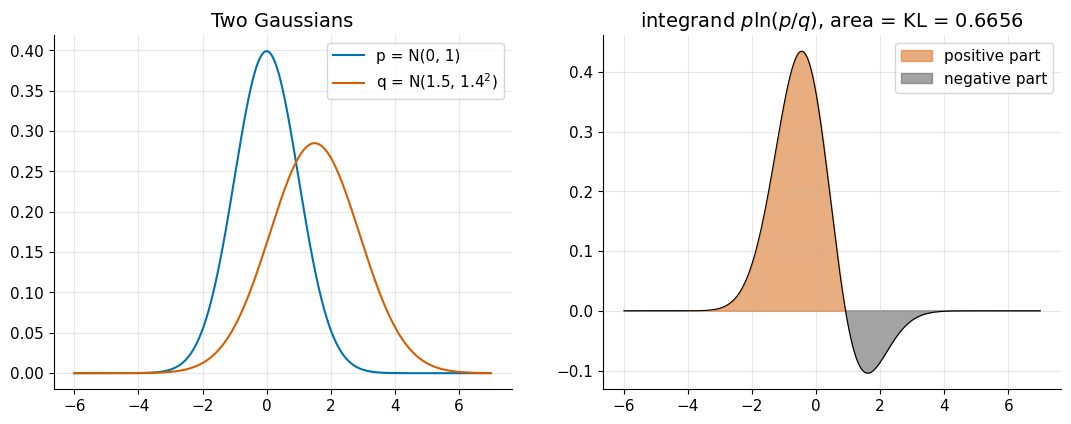

numerical KL: 0.6655538729177458 | closed form: 0.6655538692742742 | reverse: 1.268527763378787


In [3]:
x = np.linspace(-6, 7, 2000); p_ = stats.norm.pdf(x, 0, 1); q_ = stats.norm.pdf(x, 1.5, 1.4); integ = p_ * np.log(p_ / q_); kl_num = np.trapezoid(integ, x)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); axes[0].plot(x, p_, color=MAIN, label="p = N(0, 1)"); axes[0].plot(x, q_, color=HIGHLIGHT, label="q = N(1.5, 1.4$^2$)"); axes[0].legend(); axes[0].set_title("Two Gaussians")
axes[1].fill_between(x, integ, where=integ > 0, color=HIGHLIGHT, alpha=0.5, label="positive part"); axes[1].fill_between(x, integ, where=integ < 0, color=NEUTRAL, alpha=0.6, label="negative part"); axes[1].plot(x, integ, color="black", linewidth=0.8); axes[1].legend(); axes[1].set_title(f"integrand $p\\ln(p/q)$, area = KL = {kl_num:.4f}")
plt.show(); print("numerical KL:", kl_num, "| closed form:", klg(0, 1, 1.5, 1.4), "| reverse:", klg(1.5, 1.4, 0, 1)); assert abs(kl_num - klg(0, 1, 1.5, 1.4)) < 1e-6

### 8.2 KL is asymmetric
For $p=N(0,1)$ and $q=N(0,\sigma^2)$ the two directions differ: a $q$ that is too narrow is punished much harder under $\mathrm{KL}(p\|q)$ than a $q$ that is too wide, while $\mathrm{KL}(q\|p)$ does the opposite.

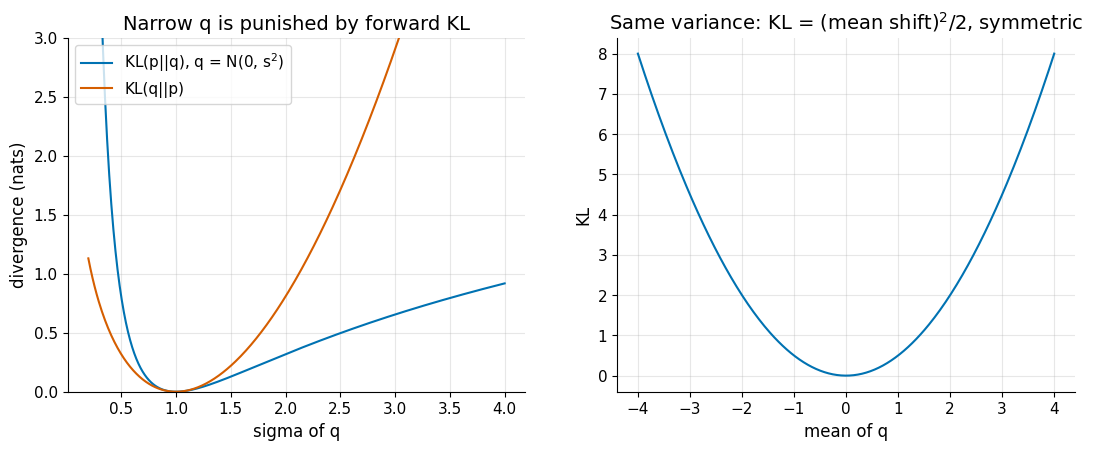

KL(p||q), KL(q||p) at sigma_q = 0.5: 0.8068528194400546 0.3181471805599453 | at sigma_q = 2: 0.3181471805599453 0.8068528194400546


In [4]:
sg = np.linspace(0.2, 4, 400); fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(sg, klg(0, 1, 0, sg), color=MAIN, label="KL(p||q), q = N(0, s$^2$)"); axes[0].plot(sg, klg(0, sg, 0, 1), color=HIGHLIGHT, label="KL(q||p)"); axes[0].set_ylim(0, 3); axes[0].set_xlabel("sigma of q"); axes[0].set_ylabel("divergence (nats)"); axes[0].legend(); axes[0].set_title("Narrow q is punished by forward KL")
mu = np.linspace(-4, 4, 300); axes[1].plot(mu, klg(0, 1, mu, 1), color=MAIN); axes[1].set_xlabel("mean of q"); axes[1].set_ylabel("KL"); axes[1].set_title("Same variance: KL = (mean shift)$^2$/2, symmetric")
plt.show(); print("KL(p||q), KL(q||p) at sigma_q = 0.5:", klg(0, 1, 0, 0.5), klg(0, 0.5, 0, 1), "| at sigma_q = 2:", klg(0, 1, 0, 2), klg(0, 2, 0, 1))
assert klg(0, 1, 0, 0.5) > klg(0, 1, 0, 2) and klg(0, 0.5, 0, 1) < klg(0, 2, 0, 1) and abs(klg(0, 1, 1.7, 1) - klg(1.7, 1, 0, 1)) < 1e-12

### 8.3 Forward and reverse KL on a bimodal target
The target is the mixture $p=\frac12N(-3,1)+\frac12N(3,1)$. We fit a single Gaussian $q=N(m,s^2)$ by minimising each direction numerically. **Forward** KL $\mathrm{KL}(p\|q)$ matches the mean and variance of $p$ (mean 0, variance 10) and sits between the peaks; **reverse** KL $\mathrm{KL}(q\|p)$ picks one peak.

forward KL: mean -0.000, sd 3.162 (moment matching: mean 0, sd 3.162), KL = 0.462
reverse KL: mean 2.984, sd 1.023 (or mean -2.984), KL = 0.689


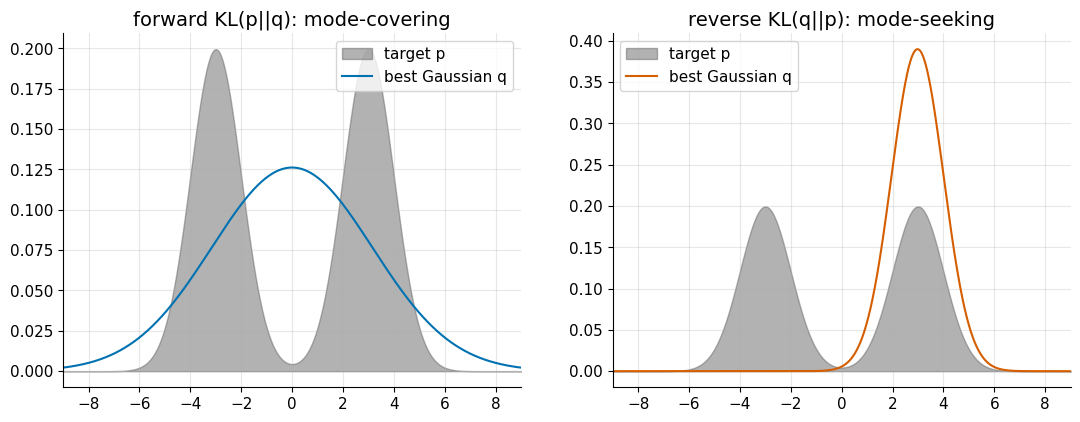

In [5]:
from scipy.optimize import minimize
xg = np.linspace(-14, 14, 6000); pm = 0.5 * stats.norm.pdf(xg, -3, 1) + 0.5 * stats.norm.pdf(xg, 3, 1)
def fkl(th): q = stats.norm.pdf(xg, th[0], np.exp(th[1])); return np.trapezoid(pm * (np.log(pm + 1e-300) - np.log(q + 1e-300)), xg)
def rkl(th): q = stats.norm.pdf(xg, th[0], np.exp(th[1])); return np.trapezoid(q * (np.log(q + 1e-300) - np.log(pm + 1e-300)), xg)
fw = minimize(fkl, [1.0, 1.0], method="Nelder-Mead"); rv = minimize(rkl, [2.5, 0.0], method="Nelder-Mead"); rv2 = minimize(rkl, [-2.5, 0.0], method="Nelder-Mead")
print(f"forward KL: mean {fw.x[0]:.3f}, sd {np.exp(fw.x[1]):.3f} (moment matching: mean 0, sd {np.sqrt(10):.3f}), KL = {fw.fun:.3f}")
print(f"reverse KL: mean {rv.x[0]:.3f}, sd {np.exp(rv.x[1]):.3f} (or mean {rv2.x[0]:.3f}), KL = {rv.fun:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, sol, nm, colr in zip(axes, [fw, rv], ["forward KL(p||q): mode-covering", "reverse KL(q||p): mode-seeking"], [MAIN, HIGHLIGHT]): ax.fill_between(xg, pm, color=NEUTRAL, alpha=0.5, label="target p"); ax.plot(xg, stats.norm.pdf(xg, sol.x[0], np.exp(sol.x[1])), color=colr, label="best Gaussian q"); ax.set_xlim(-9, 9); ax.legend(); ax.set_title(nm)
plt.show(); assert abs(fw.x[0]) < 0.02 and abs(np.exp(fw.x[1]) - np.sqrt(10)) < 0.02 and abs(abs(rv.x[0]) - 3) < 0.15 and np.exp(rv.x[1]) < 1.2

## 9. 3D visuals

### 9.1 Static: $\mathrm{KL}\big(N(\mu,\sigma^2)\,\|\,N(0,1)\big)$ over $(\mu,\sigma)$
A bowl with its minimum (0) at $(\mu,\sigma)=(0,1)$: quadratic in the mean shift, and steeper for narrow $\sigma$ than for wide $\sigma$ in the scale direction.

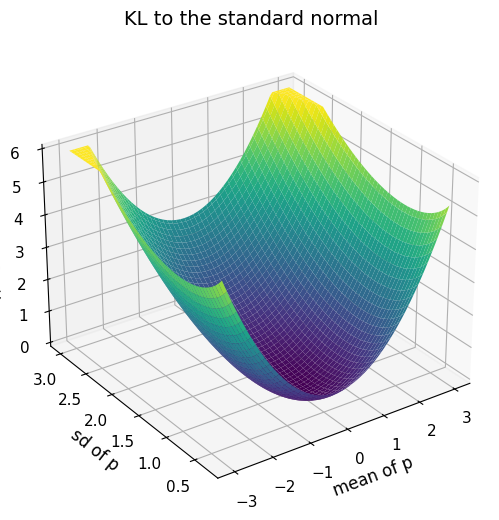

In [6]:
mus = np.linspace(-3, 3, 100); sgs = np.linspace(0.3, 3, 100); M, S = np.meshgrid(mus, sgs); KLs = klg(M, S, 0, 1)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(M, S, np.minimum(KLs, 6), cmap="viridis", edgecolor="none"); ax.set_xlabel("mean of p"); ax.set_ylabel("sd of p"); ax.set_zlabel("KL(p || N(0,1))"); ax.set_title("KL to the standard normal"); ax.view_init(elev=28, azim=-125)
plt.show(); assert abs(klg(0, 1, 0, 1)) < 1e-15 and KLs.min() >= 0

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure(go.Surface(x=mus, y=sgs, z=np.minimum(KLs, 6), colorscale="Viridis")); fig.update_layout(title="KL(N(mu, s^2) || N(0,1))", width=760, height=560, scene=dict(xaxis_title="mean", yaxis_title="sd", zaxis_title="KL")); fig.show()

### 9.3 Static: Jensen-Shannon divergence between $N(0,1)$ and $N(\mu,\sigma^2)$
Computed by numerical integration. It is symmetric, saturates below $\ln2=0.693$ and flattens when the two densities barely overlap.

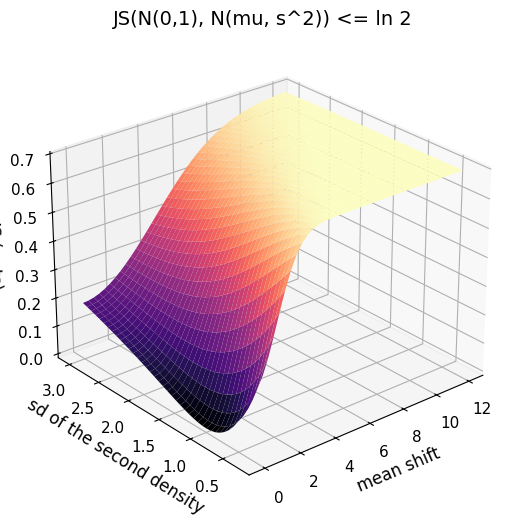

max JS on the grid: 0.6931 | ln 2 = 0.6931


In [8]:
xx = np.linspace(-25, 25, 8000); f0 = stats.norm.pdf(xx, 0, 1)
def js_gauss(m, s):
    g_ = stats.norm.pdf(xx, m, s); mm = (f0 + g_) / 2; return 0.5 * np.trapezoid(f0 * np.log(f0 / mm + 1e-300), xx) + 0.5 * np.trapezoid(g_ * np.log(g_ / mm + 1e-300), xx)
mu2 = np.linspace(0, 12, 40); sg2 = np.linspace(0.3, 3, 40); JSs = np.array([[js_gauss(m, s) for m in mu2] for s in sg2]); M2, S2 = np.meshgrid(mu2, sg2)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(M2, S2, JSs, cmap="magma", edgecolor="none"); ax.set_xlabel("mean shift"); ax.set_ylabel("sd of the second density"); ax.set_zlabel("JS (nats)"); ax.set_title("JS(N(0,1), N(mu, s^2)) <= ln 2"); ax.view_init(elev=26, azim=-130)
plt.show(); print("max JS on the grid:", JSs.max().round(4), "| ln 2 =", np.log(2).round(4)); assert JSs.max() <= np.log(2) + 1e-9 and JSs.max() > 0.65 and js_gauss(0, 1) < 1e-9

## 10. Simulation vs theory

### 10.1 Monte Carlo KL equals the closed form
$\mathrm{KL}(p\|q)=E_p[\ln p(X)/q(X)]$: average the log-density ratio over draws from $p$. For $p=N(0,1)$, $q=N(1.5,1.4^2)$ the error shrinks like $1/\sqrt n$.

In [9]:
g = np.random.default_rng(1); xs = g.normal(0, 1, 400_000); lr = stats.norm.logpdf(xs, 0, 1) - stats.norm.logpdf(xs, 1.5, 1.4); est = lr.mean(); se = lr.std(ddof=1) / np.sqrt(lr.size)
print(f"Monte Carlo {est:.5f} +/- {se:.5f} | closed form {klg(0, 1, 1.5, 1.4):.5f}"); assert abs(est - klg(0, 1, 1.5, 1.4)) < 3 * se

Monte Carlo 0.66862 +/- 0.00132 | closed form 0.66555


### 10.2 Pinsker's inequality and the quadratic approximation
For many random pairs of distributions on 6 outcomes, $\mathrm{TV}\le\sqrt{\mathrm{KL}/2}$ always holds, and for small perturbations $\mathrm{KL}\approx\frac12\sum(p-q)^2/q$.

In [10]:
g = np.random.default_rng(2); P = g.dirichlet(np.ones(6), 20_000); Q = g.dirichlet(np.ones(6), 20_000); KLr = (P * np.log(P / Q)).sum(axis=1); TV = 0.5 * np.abs(P - Q).sum(axis=1)
print("Pinsker violations:", int((TV > np.sqrt(KLr / 2) + 1e-12).sum()), "of 20,000 | smallest slack:", float((np.sqrt(KLr / 2) - TV).min().round(4)))
P0 = g.dirichlet(np.ones(6) * 20, 5000); Q0 = P0 * (1 + 0.02 * g.standard_normal(P0.shape)); Q0 /= Q0.sum(axis=1, keepdims=True); k1 = (P0 * np.log(P0 / Q0)).sum(axis=1); k2 = 0.5 * ((P0 - Q0) ** 2 / Q0).sum(axis=1)
print(f"small perturbations: median ratio KL / quadratic approximation {np.median(k1 / k2):.4f}")
assert (TV <= np.sqrt(KLr / 2) + 1e-12).all() and abs(np.median(k1 / k2) - 1) < 0.02

Pinsker violations:

 0 of 20,000 | smallest slack: 0.0037
small perturbations: median ratio KL / quadratic approximation 0.9998


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("KL(p||q): stats.entropy(p, q) | scipy.special.rel_entr(p, q).sum() | JS: scipy.spatial.distance.jensenshannon(p, q) ** 2 (it returns the square root)")
from scipy.special import rel_entr
print("rel_entr sum:", rel_entr(pa, qa).sum(), "| entropy:", stats.entropy(pa, qa), "| Gaussian KL closed form:", klg(0, 1, 1.5, 1.4))
cnts = np.array([18, 22, 20, 25, 17, 18]); print("G-test: stats.power_divergence(counts, lambda_='log-likelihood') =", stats.power_divergence(cnts, lambda_="log-likelihood"), "| = 2 n KL(p_hat || uniform):", 2 * cnts.sum() * kl(cnts / cnts.sum(), np.ones(6) / 6))
print("PSI = KL(p||q) + KL(q||p) = np.sum((q - p) * np.log(q / p)):", np.sum((qa - pa) * np.log(qa / pa)), "=", kl(pa, qa) + kl(qa, pa))
assert abs(rel_entr(pa, qa).sum() - kl(pa, qa)) < 1e-12 and abs(stats.power_divergence(cnts, lambda_="log-likelihood")[0] - 2 * cnts.sum() * kl(cnts / cnts.sum(), np.ones(6) / 6)) < 1e-9

KL(p||q): stats.entropy(p, q) | scipy.special.rel_entr(p, q).sum() | JS: scipy.spatial.distance.jensenshannon(p, q) ** 2 (it returns the square root)
rel_entr sum: 0.1837868973868122 | entropy: 0.18378689738681242 | Gaussian KL closed form: 0.6655538692742742
G-test: stats.power_divergence(counts, lambda_='log-likelihood') = Power_divergenceResult(statistic=np.float64(2.239224746812945), pvalue=np.float64(0.8151503948200314)) | = 2 n KL(p_hat || uniform): 2.2392247468129542
PSI = KL(p||q) + KL(q||p) = np.sum((q - p) * np.log(q / p)): 0.37582889054861035 = 0.37582889054861035


## 12. Real-world worked examples

---
### Example 1 (main): is the live data drifting away from the training data?

**Scenario.** A credit model was trained on applicants whose monthly income fell into five bands with shares $p=(10,25,30,20,15)\ \%$. In the last week $n=2{,}000$ applicants arrived with shares $q=(8,20,28,24,20)\ \%$ (rounded true shares of the new population). Is this drift?

**Questions**
1. Compute $\mathrm{KL}(q\|p)$, $\mathrm{KL}(p\|q)$, the PSI, the JS divergence and the total variation.
2. How large would $\mathrm{KL}(\hat q\|p)$ be from sampling noise alone with $n=2{,}000$ applicants and no real drift? (Compare with $(K-1)/(2n)$.)
3. Is the observed value of this week's sample compatible with no drift (a Monte Carlo p-value)? Also apply the G-test.
4. How many applicants per week do we need before a drift of this size is reliably detected?

### 12.1 By hand
**Q1.** $\mathrm{PSI}=\sum(q_k-p_k)\ln\frac{q_k}{p_k}$: $(-0.02)\ln0.8+(-0.05)\ln0.8+(-0.02)\ln\frac{28}{30}+(0.04)\ln1.2+(0.05)\ln\frac{4}{3}=0.00446+0.01116+0.00138+0.00729+0.01438=0.0387$. **Q2.** With $K=5$ bins the noise floor is $(K-1)/(2n)=4/4000=0.001$ for the KL of a sample against the truth. **Q3.** the G statistic is $2n\,\mathrm{KL}(\hat q\|p)$ with 4 degrees of freedom: for a true $\mathrm{KL}(q\|p)\approx0.0195$ the expected $G$ is about $2\cdot2000\cdot0.0195=78$ (about 82 with the noise term; far above the null mean of 4).

In [12]:
p_tr = np.array([0.10, 0.25, 0.30, 0.20, 0.15]); q_live = np.array([0.08, 0.20, 0.28, 0.24, 0.20]); n_live = 2000
tabs = {"KL(q||p)": kl(q_live, p_tr), "KL(p||q)": kl(p_tr, q_live), "PSI": np.sum((q_live - p_tr) * np.log(q_live / p_tr)), "JS": js(p_tr, q_live), "TV": 0.5 * np.abs(p_tr - q_live).sum()}
print({k: round(v, 5) for k, v in tabs.items()}); print("noise floor (K - 1) / (2 n) =", 4 / (2 * n_live), "| G-test mean under the alternative about", round(2 * n_live * tabs["KL(q||p)"], 1))
g = np.random.default_rng(21); null = g.multinomial(n_live, p_tr, size=100_000) / n_live; with_ = np.where(null > 0, null * np.log(np.where(null > 0, null, 1) / p_tr), 0).sum(axis=1)
obs_c = g.multinomial(n_live, q_live); obs_hat = obs_c / n_live; kl_obs = kl(obs_hat, p_tr); pval = (with_ >= kl_obs).mean(); G = 2 * n_live * kl_obs; gp = stats.chi2.sf(G, 4)
print(f"null KL(q_hat||p): mean {with_.mean():.5f} (theory {4 / (2 * n_live)}), 95th percentile {np.quantile(with_, 0.95):.5f}, 99.9th {np.quantile(with_, 0.999):.5f}")
print(f"this week: counts {obs_c}, KL(q_hat||p) = {kl_obs:.5f}, G = {G:.2f}, Monte Carlo p = {pval:.5f}, chi-square p = {gp:.3e} (scipy: {stats.power_divergence(obs_c, n_live * p_tr, lambda_='log-likelihood').pvalue:.3e})")

{'KL(q||p)': np.float64(0.0195), 'KL(p||q)': np.float64(0.01918), 'PSI': np.float64(0.03868), 'JS': np.float64(0.00482), 'TV': np.float64(0.09)}
noise floor (K - 1) / (2 n) = 0.001 | G-test mean under the alternative about 78.0


null KL(q_hat||p): mean 0.00100 (theory 0.001), 95th percentile 0.00238, 99.9th 0.00446
this week: counts [168 368 538 513 413], KL(q_hat||p) = 0.02944, G = 117.78, Monte Carlo p = 0.00000, chi-square p = 1.593e-24 (scipy: 1.593e-24)


### 12.2 Asserts

In [13]:
assert abs(tabs["PSI"] - (kl(q_live, p_tr) + kl(p_tr, q_live))) < 1e-12 and 0 < tabs["JS"] < np.log(2) and tabs["TV"] <= np.sqrt(tabs["KL(q||p)"] / 2)
assert abs(with_.mean() - 4 / (2 * n_live)) < 0.0001 and abs(G - stats.power_divergence(obs_c, n_live * p_tr, lambda_="log-likelihood").statistic) < 1e-8
assert pval < 0.001 and gp < 1e-6 and 0.03 < tabs["PSI"] < 0.05
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
Under no drift the statistic $G=2n\,\mathrm{KL}(\hat q\|p)$ follows $\chi^2_4$: compare its simulated mean, variance and upper quantile with the theory.

In [14]:
Gs = 2 * n_live * with_; print(f"G under no drift: mean {Gs.mean():.3f} (chi2_4 mean 4), variance {Gs.var():.2f} (8), 95th percentile {np.quantile(Gs, 0.95):.3f} (chi2: {stats.chi2.ppf(0.95, 4):.3f})")
assert abs(Gs.mean() - 4) < 0.05 and abs(Gs.var() - 8) < 0.3 and abs(np.quantile(Gs, 0.95) - stats.chi2.ppf(0.95, 4)) < 0.15

G under no drift: mean 4.003 (chi2_4 mean 4), variance 7.97 (8), 95th percentile 9.517 (chi2: 9.488)


### 12.4 Plots and detection power

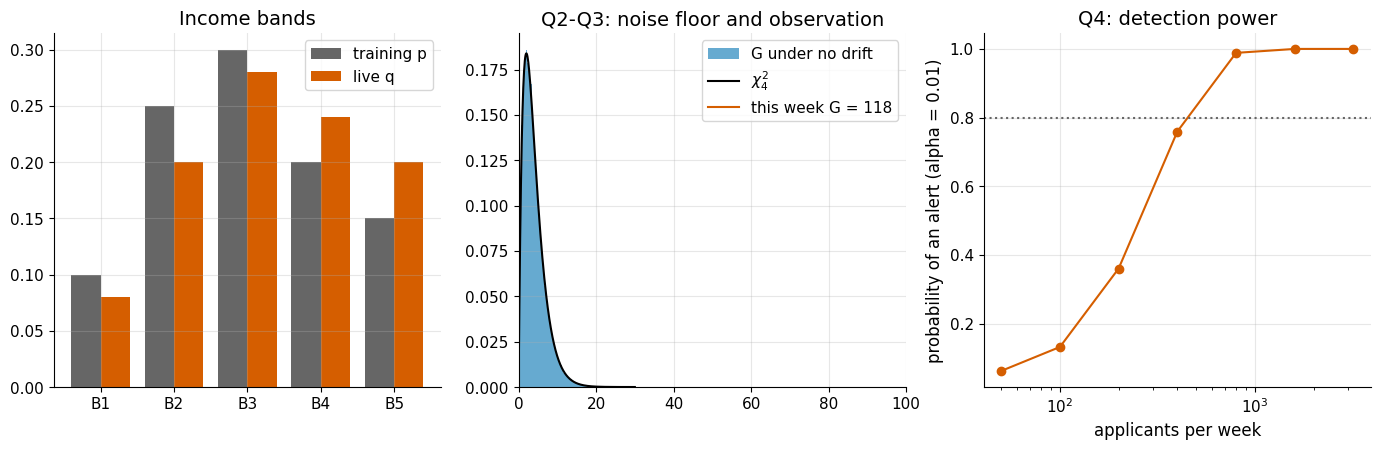

power by n: {50: 0.062, 100: 0.132, 200: 0.36, 400: 0.76, 800: 0.988, 1600: 1.0, 3200: 1.0} | first n with power >= 80%: 800


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6)); xb = np.arange(5); axes[0].bar(xb - 0.2, p_tr, 0.4, color=NEUTRAL, label="training p"); axes[0].bar(xb + 0.2, q_live, 0.4, color=HIGHLIGHT, label="live q"); axes[0].set_xticks(xb); axes[0].set_xticklabels(["B1", "B2", "B3", "B4", "B5"]); axes[0].legend(); axes[0].set_title("Income bands")
axes[1].hist(2 * n_live * with_, bins=80, density=True, color=MAIN, alpha=0.6, label="G under no drift"); gg = np.linspace(0, 30, 300); axes[1].plot(gg, stats.chi2.pdf(gg, 4), color="black", label="$\\chi^2_4$"); axes[1].axvline(G, color=HIGHLIGHT, label=f"this week G = {G:.0f}"); axes[1].set_xlim(0, 100); axes[1].legend(); axes[1].set_title("Q2-Q3: noise floor and observation")
ns = np.array([50, 100, 200, 400, 800, 1600, 3200]); pw = []
for n_ in ns:
    crit = stats.chi2.ppf(0.99, 4); c = np.random.default_rng(int(n_)).multinomial(n_, q_live, size=4000) / n_; Gq = 2 * n_ * np.where(c > 0, c * np.log(np.where(c > 0, c, 1) / p_tr), 0).sum(axis=1); pw.append((Gq > crit).mean())
axes[2].semilogx(ns, pw, "o-", color=HIGHLIGHT); axes[2].axhline(0.8, color=NEUTRAL, linestyle=":"); axes[2].set_xlabel("applicants per week"); axes[2].set_ylabel("probability of an alert (alpha = 0.01)"); axes[2].set_title("Q4: detection power")
plt.show(); n80 = ns[np.argmax(np.array(pw) >= 0.8)]; print("power by n:", dict(zip(ns.tolist(), np.round(pw, 3).tolist())), "| first n with power >= 80%:", n80)
assert pw[-1] > 0.99 and pw[0] < pw[-1]

### 12.5 Interpretation and decision (Example 1)
- The divergences between the training shares $p$ and the live shares $q$ are small: $\mathrm{KL}(q\|p)=$ **0.0195**, $\mathrm{KL}(p\|q)=$ **0.0192**, **PSI 0.0387**, JS **0.0048** (the maximum is $\ln2=0.693$) and total variation **0.09** (9 % of the applicants sit in a different band). Pinsker's bound $\sqrt{0.0195/2}=0.099$ is respected.
- **Noise floor.** With no drift and $n=2{,}000$ the sample KL averages **0.0010** (theory $(K-1)/(2n)=0.001$), with a 95th percentile of 0.0024 and a 99.9th percentile of 0.0045. This week's sample gave **0.0294** (counts 168, 368, 538, 513, 413), $G=2n\,\mathrm{KL}=$ **117.8**, far beyond the $\chi^2_4$ 95th percentile 9.49: the Monte Carlo p-value is below $10^{-5}$ (none of 100,000 null samples reached it) and the chi-square p-value is $1.6\times10^{-24}$. Under no drift $G$ has mean 4.00, variance 7.97 and 95th percentile 9.52, as the $\chi^2_4$ distribution says.
- **The two answers disagree, and both are right.** The drift is statistically certain, but its size (PSI 0.039) is below the 0.1 convention for "moderate". Detection needs about 800 applicants per week for 80 % power at $\alpha=0.01$ (power 76 % at 400, 98.8 % at 800).
- **Decision.** Treat this as a real but small shift: log it, watch whether the PSI keeps growing and check the model's performance on the new bands; do not retrain on the PSI alone. Always compare a measured divergence with the noise floor for your $n$ and bins before applying a fixed threshold.

---
### Example 2: which direction of KL should a model minimise?

**Scenario.** Customer spending is bimodal (a group around 20 and a group around 80, each with SD 8, in equal shares). A single-Gaussian model must summarise it. Compare the Gaussian chosen by **forward** KL (maximum likelihood) with the one chosen by **reverse** KL (variational inference).

**Questions.** (1) What are the best-fitting $(m,s)$ in each direction and the achieved divergences? (2) How much of the real customers does each model cover (probability mass of $q$ in the interval 12 to 28, around the lower group)? (3) Which model would you use to simulate customers, and which to describe the most typical customer?

Q1 forward: m = 50.00, s = 31.05 (mean 50, sd 31.05), KL(p||q) = 0.663, KL(q||p) of that fit = 1.645
Q1 reverse: m = 79.99, s = 8.02 (other solution m = 20.01), KL(q||p) = 0.693, KL(p||q) of that fit = 13.310
Q2 mass in [12, 28]: truth 0.341, forward fit 0.129, reverse fit (upper mode) 0.000, reverse (lower mode) 0.682
customers simulated from the forward fit that fall in the empty gap [40, 60]: 0.252; true share of customers there: 0.0062


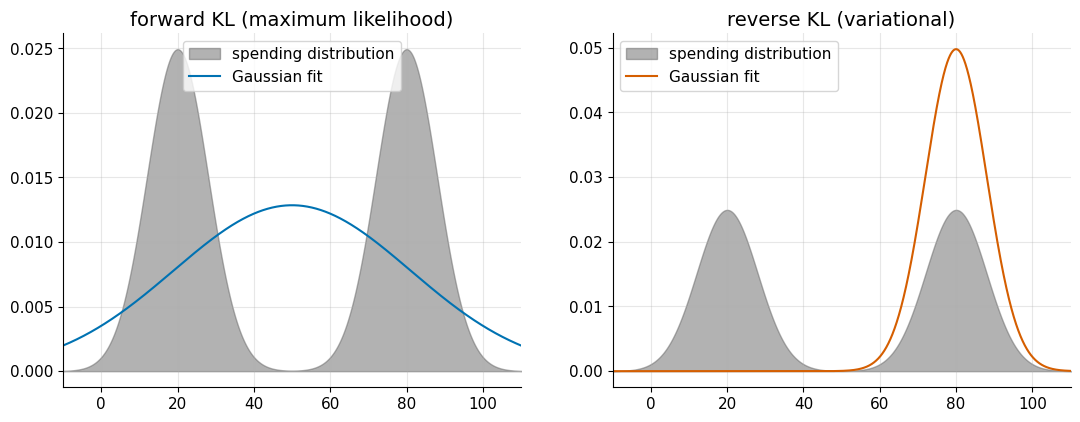

In [16]:
xg2 = np.linspace(-40, 140, 9000); pm2 = 0.5 * stats.norm.pdf(xg2, 20, 8) + 0.5 * stats.norm.pdf(xg2, 80, 8)
def fkl2(th): q = stats.norm.pdf(xg2, th[0], np.exp(th[1])); return np.trapezoid(pm2 * (np.log(pm2 + 1e-300) - np.log(q + 1e-300)), xg2)
def rkl2(th): q = stats.norm.pdf(xg2, th[0], np.exp(th[1])); return np.trapezoid(q * (np.log(q + 1e-300) - np.log(pm2 + 1e-300)), xg2)
f2 = minimize(fkl2, [40.0, 3.0], method="Nelder-Mead"); r2 = minimize(rkl2, [75.0, 2.0], method="Nelder-Mead"); r2b = minimize(rkl2, [25.0, 2.0], method="Nelder-Mead"); mean_t = 50; sd_t = np.sqrt(8 ** 2 + 30 ** 2)
print(f"Q1 forward: m = {f2.x[0]:.2f}, s = {np.exp(f2.x[1]):.2f} (mean {mean_t}, sd {sd_t:.2f}), KL(p||q) = {f2.fun:.3f}, KL(q||p) of that fit = {rkl2(f2.x):.3f}")
print(f"Q1 reverse: m = {r2.x[0]:.2f}, s = {np.exp(r2.x[1]):.2f} (other solution m = {r2b.x[0]:.2f}), KL(q||p) = {r2.fun:.3f}, KL(p||q) of that fit = {fkl2(r2.x):.3f}")
mass = lambda sol: stats.norm.cdf(28, sol.x[0], np.exp(sol.x[1])) - stats.norm.cdf(12, sol.x[0], np.exp(sol.x[1]))
print(f"Q2 mass in [12, 28]: truth {np.trapezoid(pm2[(xg2 >= 12) & (xg2 <= 28)], xg2[(xg2 >= 12) & (xg2 <= 28)]):.3f}, forward fit {mass(f2):.3f}, reverse fit (upper mode) {mass(r2):.3f}, reverse (lower mode) {mass(r2b):.3f}")
g = np.random.default_rng(23); sim_f = g.normal(f2.x[0], np.exp(f2.x[1]), 100_000); print(f"customers simulated from the forward fit that fall in the empty gap [40, 60]: {np.mean((sim_f > 40) & (sim_f < 60)):.3f}; true share of customers there: {np.trapezoid(pm2[(xg2 >= 40) & (xg2 <= 60)], xg2[(xg2 >= 40) & (xg2 <= 60)]):.4f}")
assert abs(f2.x[0] - mean_t) < 0.2 and abs(np.exp(f2.x[1]) - sd_t) < 0.2 and abs(abs(r2.x[0] - 50) - 30) < 1.5 and np.exp(r2.x[1]) < 10
assert fkl2(f2.x) < fkl2(r2.x) and rkl2(r2.x) < rkl2(f2.x)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, sol, nm, colr in zip(axes, [f2, r2], ["forward KL (maximum likelihood)", "reverse KL (variational)"], [MAIN, HIGHLIGHT]): ax.fill_between(xg2, pm2, color=NEUTRAL, alpha=0.5, label="spending distribution"); ax.plot(xg2, stats.norm.pdf(xg2, sol.x[0], np.exp(sol.x[1])), color=colr, label="Gaussian fit"); ax.set_xlim(-10, 110); ax.legend(); ax.set_title(nm)
plt.show()

### 12.7 Interpretation and decision (Example 2)
- **Forward KL** (maximum likelihood) gives $m=50.00$, $s=31.05$ (exactly the mean and SD of the bimodal distribution) with $\mathrm{KL}(p\|q)=0.663$. **Reverse KL** locks onto one group: $m=79.99$, $s=8.02$ (or $m=20.01$ for the other group), $\mathrm{KL}(q\|p)=0.693=\ln2$, the cost of ignoring one of two equal groups. Each fit is poor in the *other* direction: the forward fit has $\mathrm{KL}(q\|p)=1.645$ and the reverse fit has $\mathrm{KL}(p\|q)=13.3$.
- Probability mass in the lower group's range [12, 28]: truth **0.341**, forward fit 0.129, reverse fit on the upper mode **0.000** (and 0.682 on the lower mode). A model simulated from the forward fit places **25.2 %** of the customers in the gap between 40 and 60, where only **0.6 %** of the real customers are.
- **Decision.** Use the forward fit (maximum likelihood) to describe how spread out spending is, for example for risk bounds that must cover both groups; use the reverse fit only to describe one typical group; do not simulate customers from a single Gaussian, use a two-component mixture instead.

---
### Example 3: KL is the statistic behind the G-test

**Scenario.** A die is rolled 600 times to test whether it is fair. The die is slightly loaded: $P(6)=0.20$ and $0.16$ for each other face. Test fairness with the G-test (KL against the uniform) and with Pearson's chi-square.

**Questions.** (1) What are $G=2n\,\mathrm{KL}(\hat p\|\text{uniform})$, Pearson's $\chi^2$ and their p-values? (2) How often does the test reject a fair die at the 5 % level, and a die loaded as above? (3) What is the smallest loading of face 6 that is detected 80 % of the time?

counts [ 99  82 112 125  78 104]: G = 16.034 (p = 0.0067), Pearson chi2 = 15.940 (p = 0.0070); scipy: 0.0067, 0.0070
Q2: rejection rate for a fair die 0.0508 (nominal 0.05), for the loaded die 0.3337


Q3: power by P(6): {0.17: 0.058, 0.18: 0.093, 0.19: 0.176, 0.2: 0.336, 0.21: 0.536, 0.22: 0.742, 0.23: 0.883, 0.24: 0.961, 0.25: 0.984, 0.26: 0.996, 0.27: 0.999, 0.28: 1.0, 0.29: 1.0, 0.3: 1.0} | smallest loading with power >= 80%: 0.23
noncentral chi-square: KL = 0.00381, G has non-centrality 2 n KL; power 80% needs n = 1685 rolls (power at n = 600: 0.332)


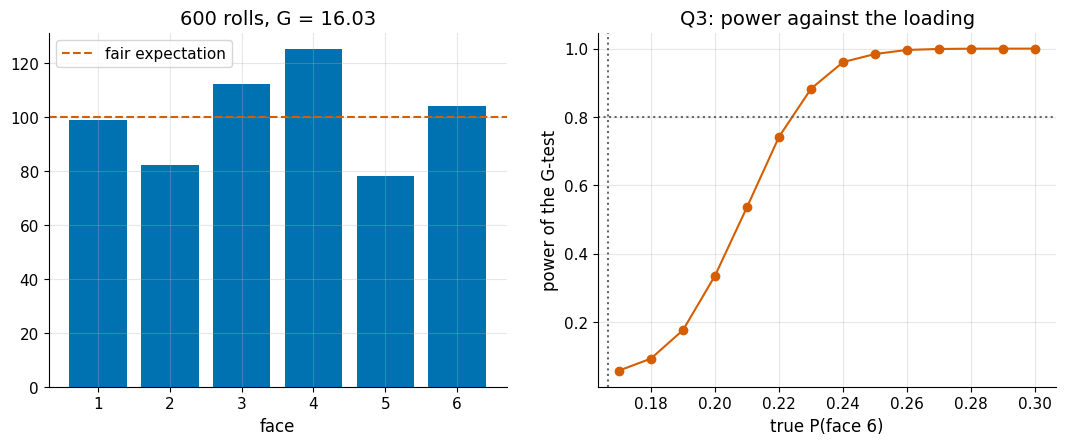

In [17]:
pl = np.array([0.16] * 5 + [0.20]); u6 = np.ones(6) / 6; g = np.random.default_rng(24); cnt6 = g.multinomial(600, pl); G6 = 2 * 600 * kl(cnt6 / 600, u6); X2 = ((cnt6 - 100) ** 2 / 100).sum()
print(f"counts {cnt6}: G = {G6:.3f} (p = {stats.chi2.sf(G6, 5):.4f}), Pearson chi2 = {X2:.3f} (p = {stats.chi2.sf(X2, 5):.4f}); scipy: {stats.power_divergence(cnt6, lambda_='log-likelihood')[1]:.4f}, {stats.chisquare(cnt6).pvalue:.4f}")
crit = stats.chi2.ppf(0.95, 5)
def rej(p_, n, R, seed):
    c = np.random.default_rng(seed).multinomial(n, p_, size=R) / n; Gs_ = 2 * n * np.where(c > 0, c * np.log(np.where(c > 0, c, 1) / u6), 0).sum(axis=1); return (Gs_ > crit).mean()
r_fair, r_load = rej(u6, 600, 40_000, 25), rej(pl, 600, 40_000, 26); print(f"Q2: rejection rate for a fair die {r_fair:.4f} (nominal 0.05), for the loaded die {r_load:.4f}")
loads = np.linspace(0.17, 0.30, 14); pw6 = [rej(np.r_[np.full(5, (1 - l) / 5), l], 600, 6000, 27) for l in loads]; l80 = loads[np.argmax(np.array(pw6) >= 0.8)]; print("Q3: power by P(6):", dict(zip(loads.round(3).tolist(), np.round(pw6, 3).tolist())), "| smallest loading with power >= 80%:", round(float(l80), 3))
klp = kl(pl, u6); n80 = next(n for n in range(600, 4000) if stats.ncx2.sf(crit, 5, 2 * n * klp) >= 0.8); print(f"noncentral chi-square: KL = {klp:.5f}, G has non-centrality 2 n KL; power 80% needs n = {n80} rolls (power at n = 600: {stats.ncx2.sf(crit, 5, 2 * 600 * klp):.3f})")
assert abs(G6 - stats.power_divergence(cnt6, lambda_="log-likelihood")[0]) < 1e-8 and abs(r_fair - 0.05) < 0.01 and r_load > r_fair and pw6[-1] > 0.95
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); axes[0].bar(range(1, 7), cnt6, color=MAIN); axes[0].axhline(100, color=HIGHLIGHT, linestyle="--", label="fair expectation"); axes[0].legend(); axes[0].set_xlabel("face"); axes[0].set_title(f"600 rolls, G = {G6:.2f}")
axes[1].plot(loads, pw6, "o-", color=HIGHLIGHT); axes[1].axhline(0.8, color=NEUTRAL, linestyle=":"); axes[1].axvline(1 / 6, color=NEUTRAL, linestyle=":"); axes[1].set_xlabel("true P(face 6)"); axes[1].set_ylabel("power of the G-test"); axes[1].set_title("Q3: power against the loading")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- The 600 rolls (99, 82, 112, 125, 78, 104) give $G=2n\,\mathrm{KL}(\hat p\|\text{uniform})=$ **16.03**, p-value **0.0067**, and Pearson's $\chi^2=$ **15.94**, p-value 0.0070: the two statistics agree because they are two expansions of the same divergence, and `scipy` returns the same $G$.
- The G-test rejects a fair die in **5.08 %** of 40,000 trials (nominal 5 %) and the loaded die ($P(6)=0.20$) in only **33.4 %**: 600 rolls are not enough to detect a loading of 0.04 reliably. The smallest loading with power at least 80 % on the grid is $P(6)=$ **0.23** (power 74 % at 0.22 and 88 % at 0.23).
- **Decision.** To catch a die loaded like this one, roll it about **1,700 times** (the non-centrality of $G$ is $2n\,\mathrm{KL}$ with $\mathrm{KL}=0.0038$, which reaches 80 % power at $n=1{,}700$); and remember that the same arithmetic ($2n\,\mathrm{KL}$) governs every categorical goodness-of-fit test: n times the divergence, compared with a chi-square quantile.

## 13. Where it is used

### Statistics
- **Likelihood-ratio and G-tests** are $2n\,\mathrm{KL}$; AIC estimates the expected KL between a fitted model and the truth; **Fisher information** is the curvature of KL; **Bayesian updating** moves from prior to posterior by the KL that the data are worth (information gain).

### Data science
- **Data and concept drift monitoring** (PSI, KL, JS per feature and for model scores), **model comparison** and **feature distribution checks** before deployment; **A/B test guardrails** on metric distributions.

### ML and AI
- **Variational autoencoders** (KL between the encoder and the prior), **variational inference** (reverse KL), **knowledge distillation**, **policy-gradient constraints** (TRPO, PPO and the KL penalty of RLHF), **t-SNE and UMAP** (KL between neighbour distributions), original **GAN theory** (JS) and its limits.

## 14. Common pitfalls and misconceptions

- **Calling KL a distance:** it is asymmetric and violates the triangle inequality; use JS or $\sqrt{\mathrm{JS}}$ (or Wasserstein, 08_03) when a symmetric, finite measure is needed.
- **Zero probabilities:** $\mathrm{KL}(p\|q)=\infty$ if $q_k=0<p_k$; with empirical histograms add a small count or use coarser bins (PSI practice).
- **Ignoring sampling noise:** the KL of a finite sample is biased up by about $(K-1)/(2n)$; a PSI of 0.02 can be pure noise with small $n$ or many bins.
- **Rules of thumb as laws:** PSI $<0.1$ stable, $0.1$-$0.25$ moderate, $>0.25$ major are conventions, not theorems; calibrate against the null distribution for your $n$ and binning (Example 1).
- **Binning dependence:** KL of binned data depends on the bins; fix the bins on the training data.
- **Direction confusion:** forward KL is mode-covering (maximum likelihood), reverse KL is mode-seeking (variational inference); using the wrong one changes what the fit looks like (Example 2).
- **JS saturates:** two distributions with disjoint supports are $\ln2$ apart however far, so JS gives no gradient signal; this motivates the Wasserstein distance.

## 15. Exercises

1. Compute $\mathrm{KL}(p\|q)$ and $\mathrm{KL}(q\|p)$ for $p=(0.9,0.1)$ and $q=(0.6,0.4)$ and the JS divergence.
2. Compute the KL divergence $\mathrm{KL}(N(2,1)\|N(0,2^2))$ and $\mathrm{KL}(N(0,2^2)\|N(2,1))$.
3. A fair coin is compared with a coin that lands heads with probability 0.51: compute the KL in nats and the number of flips $n$ for which $2n\,\mathrm{KL}$ reaches the 5 % critical value of $\chi^2_1$ (3.84).
4. Show numerically that for the Poisson($\lambda_1$) and Poisson($\lambda_2$) distributions $\mathrm{KL}=\lambda_1\ln\frac{\lambda_1}{\lambda_2}+\lambda_2-\lambda_1$ (use $\lambda_1=4$, $\lambda_2=6$ and a long sum).
5. Compute the PSI of the score distribution of a model between two months: $p=(0.2,0.3,0.3,0.2)$, $q=(0.1,0.25,0.35,0.30)$, and compare with the 0.1 and 0.25 conventions.
6. (Harder) Show that the symmetrised KL (the PSI) between $N(0,1)$ and $N(0,s^2)$ is smallest at $s=1$, and compute it at $s=0.5$ and $s=2$.

Solutions are at the end.

## 16. Summary table

| Quantity | Formula | Properties |
|---|---|---|
| KL$(p\|q)$ | $\sum p\ln(p/q)$ | $\ge0$, asymmetric, infinite if $q=0<p$ |
| JS | $\tfrac12$KL$(p\|m)+\tfrac12$KL$(q\|m)$ | symmetric, $\le\ln2$, $\sqrt{\text{JS}}$ metric |
| PSI | $\sum(q-p)\ln(q/p)$ | KL$(p\|q)$ + KL$(q\|p)$ |
| Gaussian KL | $\ln\frac{\sigma_2}{\sigma_1}+\frac{\sigma_1^2+\Delta\mu^2}{2\sigma_2^2}-\frac12$ | closed form |
| G-test | $2n\,$KL$(\hat p\|p^0)\sim\chi^2_{K-1}$ | likelihood ratio |
| Pinsker | TV $\le\sqrt{\text{KL}/2}$ | |
| tools | `stats.entropy(p, q)`, `rel_entr`, `jensenshannon` | |

## Solutions

In [18]:
a, b = np.array([0.9, 0.1]), np.array([0.6, 0.4]); print(f"1: KL(p||q) = {kl(a, b):.4f}, KL(q||p) = {kl(b, a):.4f}, JS = {js(a, b):.4f}")
print(f"2: KL(N(2,1)||N(0,4)) = {klg(2, 1, 0, 2):.4f}, KL(N(0,4)||N(2,1)) = {klg(0, 2, 2, 1):.4f}")
kc = kl(np.array([0.51, 0.49]), np.array([0.5, 0.5])); print(f"3: KL = {kc:.6f} nats; 2 n KL = 3.84 at n = {3.841 / (2 * kc):.0f} flips")
ks = np.arange(0, 80); k_p = np.sum(stats.poisson.pmf(ks, 4) * (stats.poisson.logpmf(ks, 4) - stats.poisson.logpmf(ks, 6))); k_c = 4 * np.log(4 / 6) + 6 - 4; print(f"4: sum {k_p:.6f} vs closed form {k_c:.6f}")
pp_, qq_ = np.array([0.2, 0.3, 0.3, 0.2]), np.array([0.1, 0.25, 0.35, 0.30]); psi = np.sum((qq_ - pp_) * np.log(qq_ / pp_)); print(f"5: PSI = {psi:.4f} ({'moderate' if 0.1 <= psi < 0.25 else 'other'} by the conventions)")
sym = lambda s: klg(0, s, 0, 1) + klg(0, 1, 0, s); print(f"6: symmetrised KL at s = 0.5: {sym(0.5):.4f}, s = 2: {sym(2):.4f}, s = 1: {sym(1):.4f}; minimiser on a grid: {sg[np.argmin(sym(sg))]:.3f}")
assert abs(k_p - k_c) < 1e-9 and abs(sg[np.argmin(sym(sg))] - 1) < 0.02 and psi > 0

1: KL(p||q) = 0.2263, KL(q||p) = 0.3112, JS = 0.0633
2: KL(N(2,1)||N(0,4)) = 0.8181, KL(N(0,4)||N(2,1)) = 2.8069
3: KL = 0.000200 nats; 2 n KL = 3.84 at n = 9602 flips
4: sum 0.378140 vs closed form 0.378140
5: PSI = 0.1267 (moderate by the conventions)
6: symmetrised KL at s = 0.5: 1.1250, s = 2: 1.1250, s = 1: 0.0000; minimiser on a grid: 1.000


**1.** $\mathrm{KL}(p\|q)=$ **0.2263**, $\mathrm{KL}(q\|p)=$ **0.3112**, $\mathrm{JS}=$ **0.0633**.

**2.** $\mathrm{KL}(N(2,1)\|N(0,2^2))=\ln2+\frac{1+4}{8}-\frac12=$ **0.8181**; $\mathrm{KL}(N(0,2^2)\|N(2,1))=$ **2.8069**: the narrow density is far more costly as a model of the wide one.

**3.** $\mathrm{KL}=$ **0.000200** nats, so $2n\,\mathrm{KL}=3.84$ needs about **9,600 flips** to see a 51 % coin.

**4.** The long sum gives **0.378140**, equal to $4\ln\frac46+6-4$.

**5.** $\mathrm{PSI}=$ **0.1267**: "moderate" by the 0.1/0.25 conventions.

**6.** The symmetrised KL is **1.1250** at both $s=0.5$ and $s=2$ (it is symmetric under $s\to1/s$) and 0 at $s=1$, its minimum on the grid.